In [46]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets

train = pd.read_csv("../data/raw/train.csv")
test = pd.read_csv("../data/raw/test.csv")

# Display first 5 rows

train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# House Prices - Exploratory Data Analysis (EDA)

## 1. Import Libraries and Load Data

In [2]:

# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Set visualization style
sns.set_theme(style="whitegrid")

# Find project folder
cwd = Path.cwd()

if (cwd / "data/raw/train.csv").exists():
    project_dir = cwd
elif (cwd.parent / "data/raw/train.csv").exists():
    project_dir = cwd.parent
else:
    raise FileNotFoundError("Cannot find data/raw/train.csv")

# Load datasets
train = pd.read_csv(project_dir / "data/raw/train.csv")
test = pd.read_csv(project_dir / "data/raw/test.csv")

print("Data loaded successfully!")


Data loaded successfully!


In [3]:
# Check dataset dimensions

print("Train dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

Train dataset shape: (1460, 81)
Test dataset shape: (1459, 80)


In [4]:
# Display first 5 rows

train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
# Display last 5 rows

train.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [6]:
# Information about columns

train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [7]:
# Statistical summary

train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [8]:
# SalePrice statistics

print(train["SalePrice"].describe())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


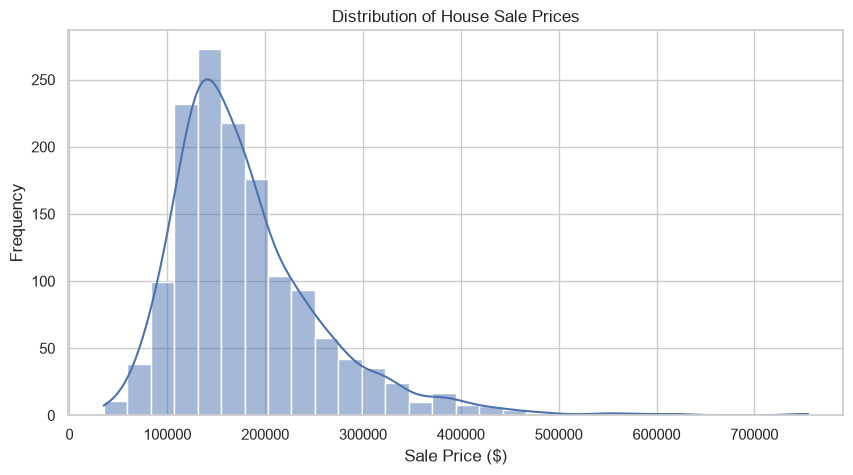

In [9]:
# Distribution of SalePrice

plt.figure(figsize=(10, 5))

sns.histplot(
    train["SalePrice"],
    kde=True,
    bins=30
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")

plt.show()

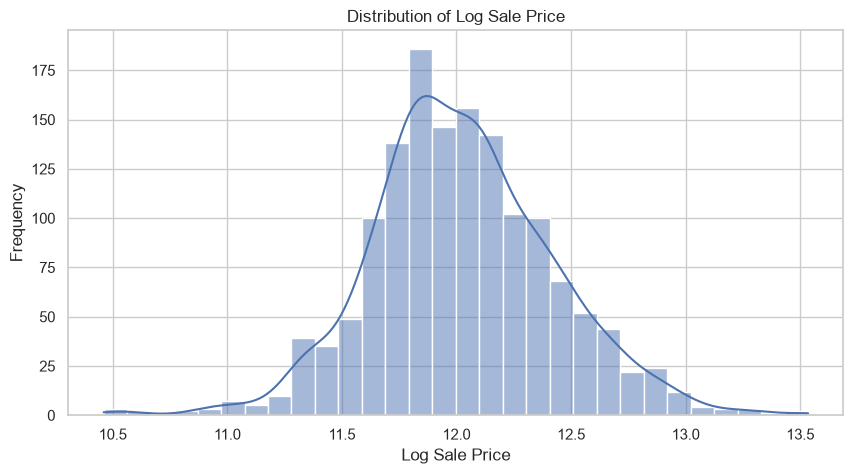

In [11]:
# Log transformation

train["SalePriceLog"] = np.log1p(train["SalePrice"])

plt.figure(figsize=(10, 5))

sns.histplot(
    train["SalePriceLog"],
    kde=True,
    bins=30
)

plt.title("Distribution of Log Sale Price")
plt.xlabel("Log Sale Price")
plt.ylabel("Frequency")

plt.show()

## 2. Missing Values Analysis

In [12]:

# Check missing values in train and test

print("Missing values in TRAIN:")
print(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nMissing values in TEST:")
print(test.isnull().sum().sort_values(ascending=False).head(20))


Missing values in TRAIN:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageYrBlt       81
GarageFinish      81
GarageType        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtFinType1      37
BsmtCond          37
MasVnrArea         8
Electrical         1
HouseStyle         0
dtype: int64

Missing values in TEST:
PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageYrBlt       78
GarageCond        78
GarageFinish      78
GarageQual        78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
BsmtHalfBath       2
dtype: int64


In [13]:

# Calculate missing values percentage

train_missing = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
})

train_missing = train_missing[
    train_missing["Missing Count"] > 0
].sort_values(by="Missing Percentage", ascending=False)

test_missing = pd.DataFrame({
    "Missing Count": test.isnull().sum(),
    "Missing Percentage": test.isnull().mean() * 100
})

test_missing = test_missing[
    test_missing["Missing Count"] > 0
].sort_values(by="Missing Percentage", ascending=False)

display(train_missing)
display(test_missing)


,Missing Count,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


,Missing Count,Missing Percentage
PoolQC,1456,99.794380
MiscFeature,1408,96.504455
Alley,1352,92.666210
Fence,1169,80.123372
MasVnrType,894,61.274846
FireplaceQu,730,50.034270
LotFrontage,227,15.558602
GarageQual,78,5.346127
GarageCond,78,5.346127
GarageYrBlt,78,5.346127


### 2.1 Handling Missing Values

In [16]:

# Create copies for data cleaning
train = train.copy()
test = test.copy()

# Separate target from features
y = train["SalePrice"].copy()

# Identify categorical and numerical columns
categorical_cols = train.select_dtypes(
    include=["object"]
).columns

numerical_cols = train.select_dtypes(
    include=["number"]
).columns.drop(
    ["SalePrice", "SalePriceLog"],
    errors="ignore"
)

# 1. Fill categorical missing values
# Most missing categorical values mean "None"

for col in categorical_cols:
    if col == "Electrical":
        mode_value = train[col].mode()[0]
        train[col] = train[col].fillna(mode_value)
        test[col] = test[col].fillna(mode_value)
    else:
        train[col] = train[col].fillna("None")
        test[col] = test[col].fillna("None")

# 2. Fill LotFrontage using Neighborhood median

neighborhood_median = train.groupby(
    "Neighborhood"
)["LotFrontage"].median()

for df in [train, test]:
    df["LotFrontage"] = df["LotFrontage"].fillna(
        df["Neighborhood"].map(neighborhood_median)
    )

    df["LotFrontage"] = df["LotFrontage"].fillna(
        train["LotFrontage"].median()
    )

# 3. Missing numerical values meaning absence

for col in ["MasVnrArea", "GarageYrBlt"]:
    train[col] = train[col].fillna(0)
    test[col] = test[col].fillna(0)

# 4. Fill remaining numerical missing values with median

for col in numerical_cols:
    median_value = train[col].median()

    train[col] = train[col].fillna(median_value)
    test[col] = test[col].fillna(median_value)

print("Missing values handled!")


Missing values handled!


C:\Users\User\AppData\Local\Temp\ipykernel_6892\362461842.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train.select_dtypes(


In [17]:
# Check remaining missing values

print("Train missing values:", train.isnull().sum().sum())
print("Test missing values:", test.isnull().sum().sum())

Train missing values: 0
Test missing values: 0


In [18]:
# Save temporary cleaned datasets

train.to_csv(
    project_dir / "data/train_cleaned_temp.csv",
    index=False
)

test.to_csv(
    project_dir / "data/test_cleaned_temp.csv",
    index=False
)

print("Cleaned datasets saved!")

Cleaned datasets saved!


## 3. Data Visualization

### 3.1 Numerical Features Distribution

In [19]:

# Create figures directory

figures_dir = project_dir / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Figures directory is ready!")


Figures directory is ready!


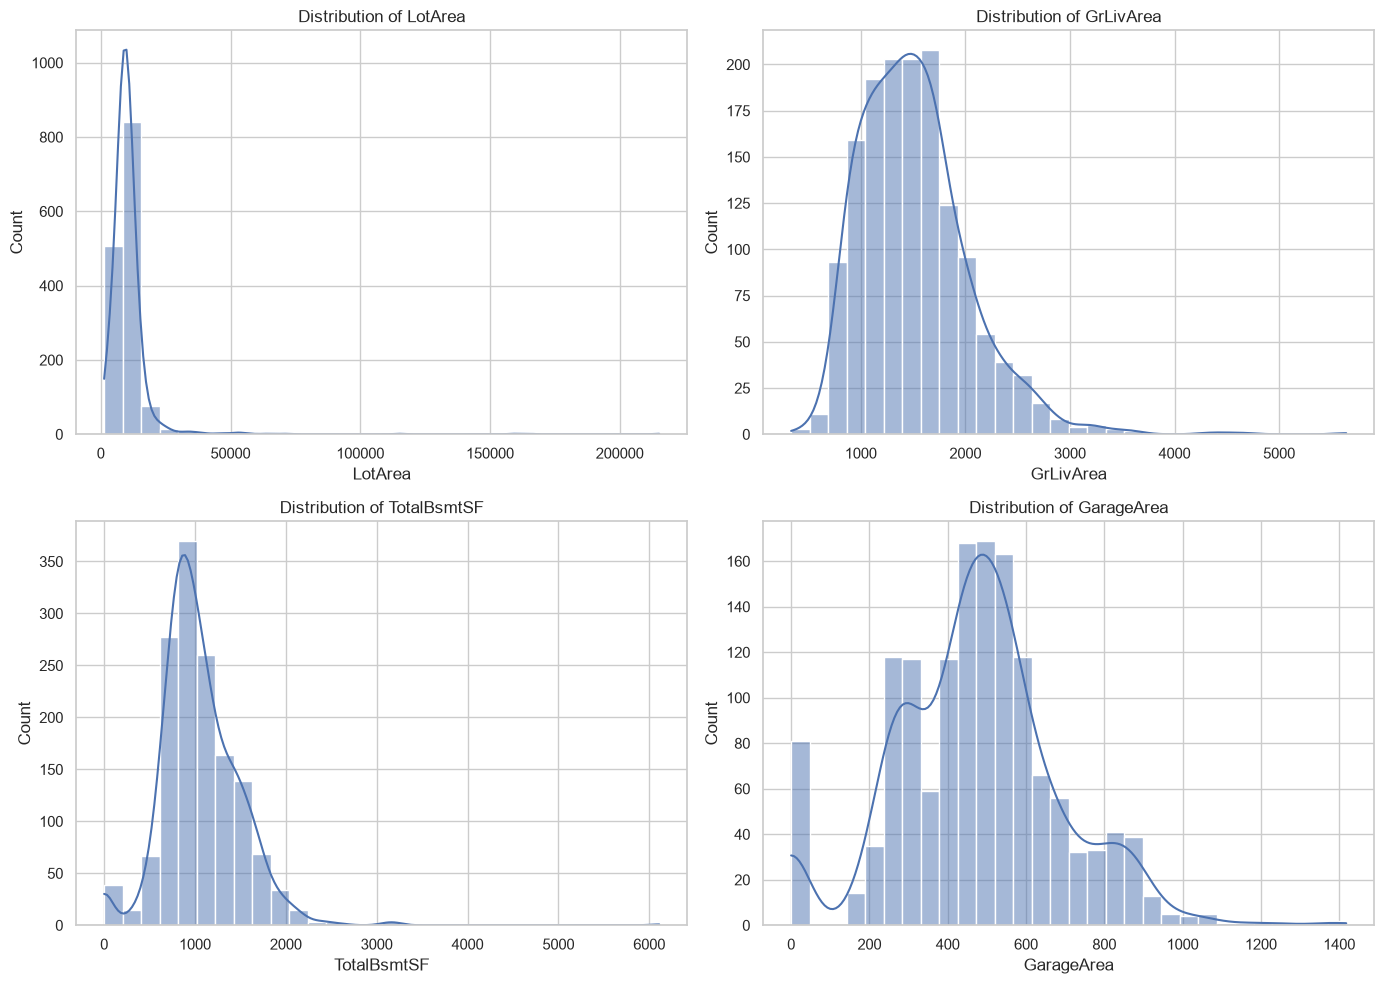

In [20]:

# Numerical feature distributions

numeric_features = [
    "LotArea",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for col, ax in zip(numeric_features, axes.flatten()):
    sns.histplot(train[col], kde=True, ax=ax, bins=30)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()

plt.savefig(
    figures_dir / "numerical_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


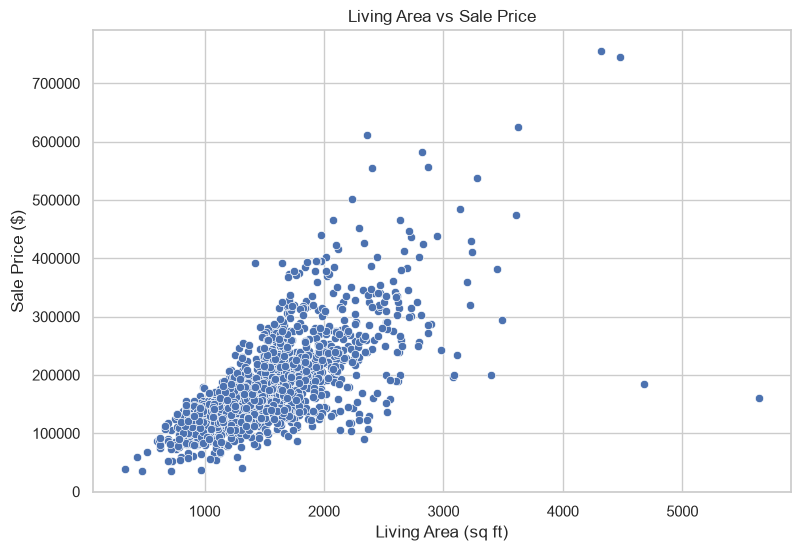

In [21]:

# Relationship between living area and sale price

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=train,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("Sale Price ($)")

plt.savefig(
    figures_dir / "living_area_vs_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


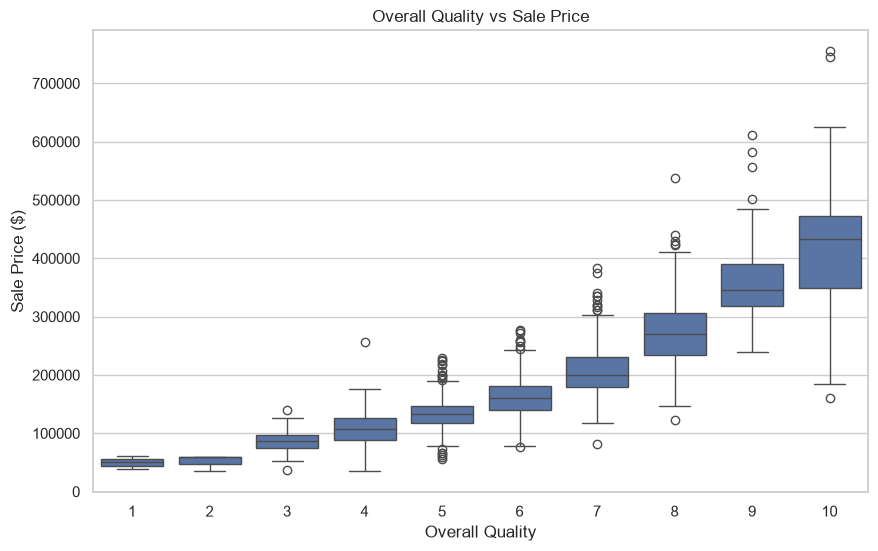

In [22]:

# Overall Quality vs Sale Price

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=train,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price ($)")

plt.savefig(
    figures_dir / "quality_vs_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


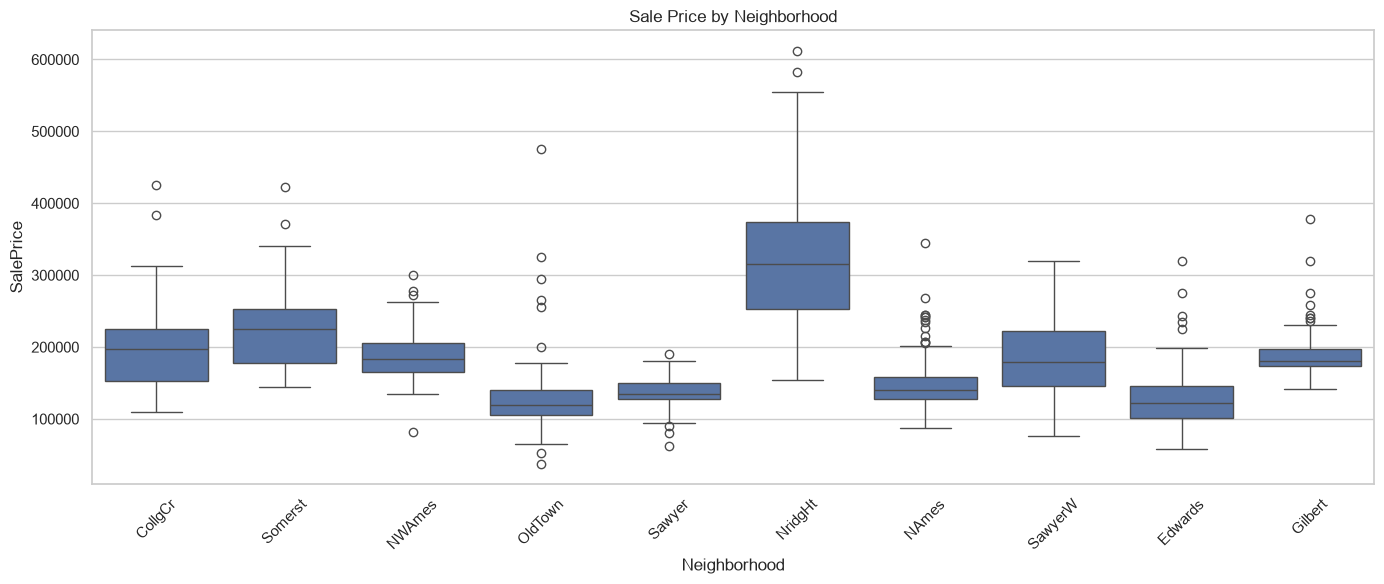

In [23]:

# Top 10 neighborhoods by number of houses

top_neighborhoods = train["Neighborhood"].value_counts().head(10).index

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=train[train["Neighborhood"].isin(top_neighborhoods)],
    x="Neighborhood",
    y="SalePrice"
)

plt.title("Sale Price by Neighborhood")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_dir / "neighborhood_vs_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
MasVnrArea      0.472614
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.349876
Name: SalePrice, dtype: float64


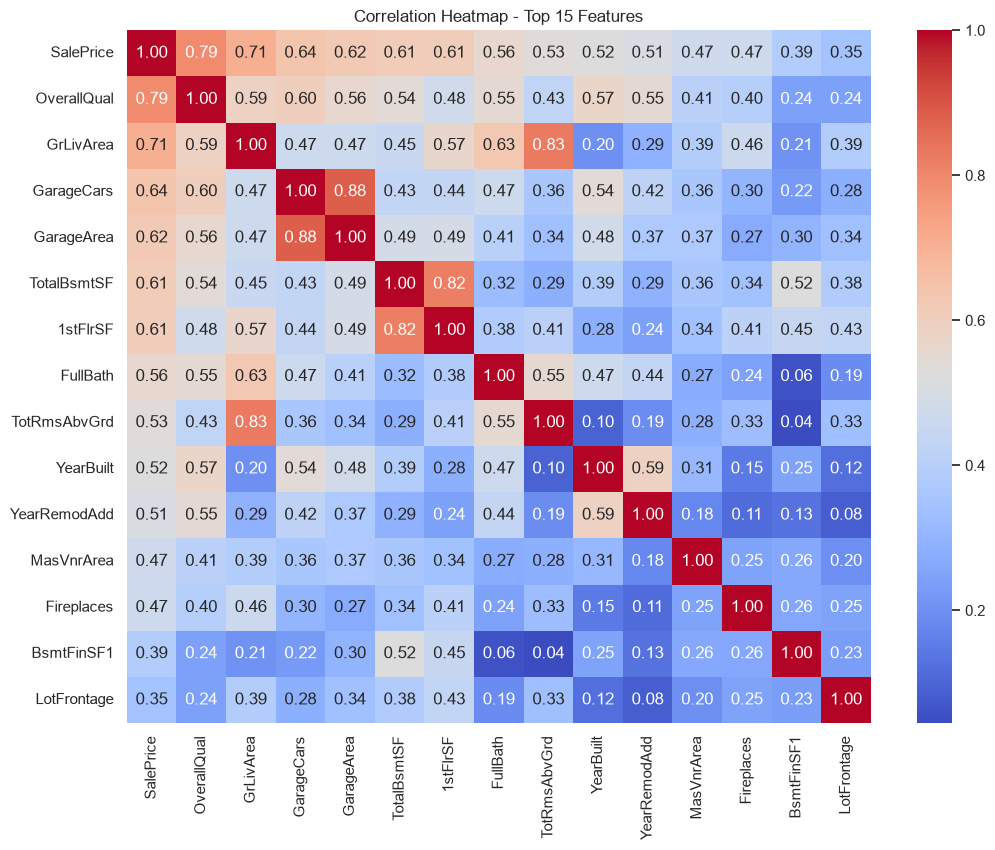

In [26]:
numeric_data = train.select_dtypes(include=["number"]).drop(
    columns=["SalePriceLog"],
    errors="ignore"
)

correlations = numeric_data.corr()["SalePrice"].sort_values(
    ascending=False
)

print(correlations.head(15))

top_features = correlations.abs().nlargest(15).index

plt.figure(figsize=(12, 9))

sns.heatmap(
    numeric_data[top_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Top 15 Features")

plt.savefig(
    figures_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Check saved figures

print("Saved figures:")

for file in figures_dir.iterdir():
    print(file.name)

Saved figures:
correlation_heatmap.png
living_area_vs_price.png
neighborhood_vs_price.png
numerical_distributions.png
quality_vs_price.png


## 4. Outlier Detection

### 4.1 Detecting Outliers Using IQR

In [28]:

# Detect outliers using IQR method

def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"Column: {column}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Number of outliers: {len(outliers)}")

    return outliers

# Check outliers
outliers_area = detect_outliers(train, "GrLivArea")
outliers_price = detect_outliers(train, "SalePrice")


Column: GrLivArea
Lower bound: 158.62
Upper bound: 2747.62
Number of outliers: 31
Column: SalePrice
Lower bound: 3937.50
Upper bound: 340037.50
Number of outliers: 61


In [29]:

# Display unusual houses

outliers_area[
    ["Id", "GrLivArea", "OverallQual", "SalePrice"]
].sort_values("GrLivArea", ascending=False)


,Id,GrLivArea,OverallQual,SalePrice
1298,1299,5642,10,160000
523,524,4676,10,184750
1182,1183,4476,10,745000
691,692,4316,10,755000
1169,1170,3627,10,625000
185,186,3608,10,475000
304,305,3493,7,295000
1268,1269,3447,8,381000
635,636,3395,6,200000
769,770,3279,8,538000


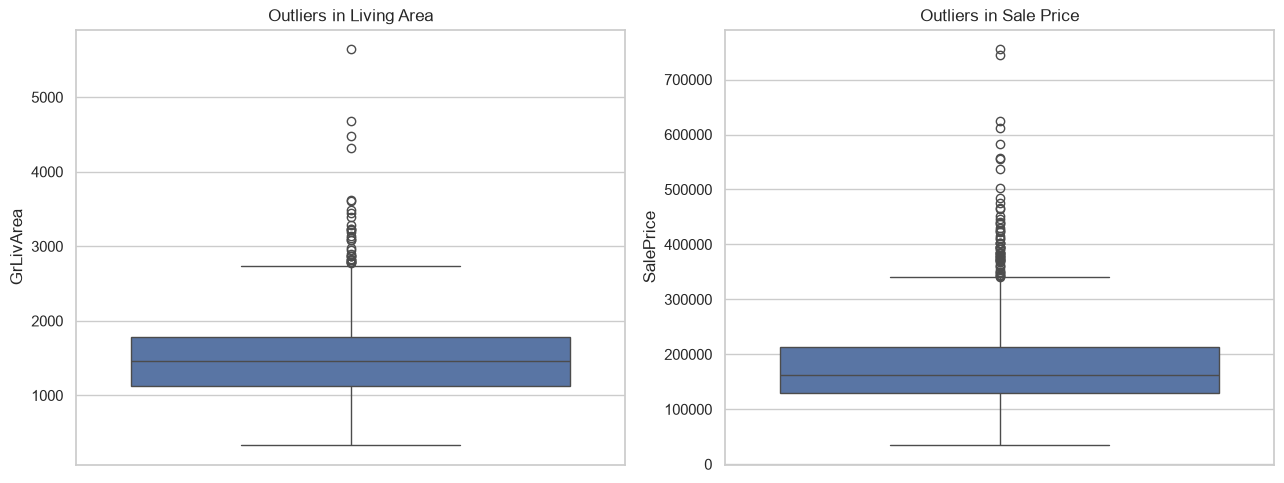

In [30]:
# Boxplot for outlier visualization

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(y=train["GrLivArea"], ax=axes[0])
axes[0].set_title("Outliers in Living Area")

sns.boxplot(y=train["SalePrice"], ax=axes[1])
axes[1].set_title("Outliers in Sale Price")

plt.tight_layout()

plt.savefig(
    figures_dir / "outliers_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# Investigate very large houses

unusual_houses = train[
    (train["GrLivArea"] > 4000) &
    (train["SalePrice"] < 300000)
]

display(
    unusual_houses[
        ["Id", "GrLivArea", "OverallQual", "SalePrice"]
    ]
)

,Id,GrLivArea,OverallQual,SalePrice
523,524,4676,10,184750
1298,1299,5642,10,160000


In [32]:
# Remove only extreme and suspicious observations

outlier_ids = unusual_houses["Id"].tolist()

train = train[
    ~train["Id"].isin(outlier_ids)
].copy()

print("Removed house IDs:", outlier_ids)
print("New train shape:", train.shape)

Removed house IDs: [524, 1299]
New train shape: (1458, 82)


### 4.2 Outlier Handling

Outliers were detected using the IQR method.

The GrLivArea and SalePrice columns were analyzed.

Extreme houses with very large living areas
and unusually low sale prices were investigated.

Only suspicious observations were removed from
the training dataset.

Other outliers were kept because they may represent
real houses with high prices or unusual characteristics.

The test dataset was not modified.

## 5. Feature Engineering

### 5.1 Updating Target Variable

In [33]:

# Update target after removing outliers

y = train["SalePrice"].copy()

print("Train shape:", train.shape)
print("Target shape:", y.shape)


Train shape: (1458, 82)
Target shape: (1458,)


In [34]:

# Create new features in train and test

for df in [train, test]:

    # 1. Total House Area
    df["TotalSF"] = (
        df["TotalBsmtSF"] +
        df["1stFlrSF"] +
        df["2ndFlrSF"]
    )

    # 2. Total Bathrooms
    df["TotalBathrooms"] = (
        df["FullBath"] +
        0.5 * df["HalfBath"] +
        df["BsmtFullBath"] +
        0.5 * df["BsmtHalfBath"]
    )

    # 3. House Age
    df["HouseAge"] = df["YrSold"] - df["YearBuilt"]

    # 4. Total Porch Area
    porch_columns = [
        "OpenPorchSF",
        "EnclosedPorch",
        "3SsnPorch",
        "ScreenPorch",
        "WoodDeckSF"
    ]

    df["TotalPorchSF"] = df[porch_columns].sum(axis=1)

print("New features created successfully!")


New features created successfully!


In [35]:
# Display new features

new_features = [
    "TotalSF",
    "TotalBathrooms",
    "HouseAge",
    "TotalPorchSF"
]

display(train[new_features + ["SalePrice"]].head(10))

,TotalSF,TotalBathrooms,HouseAge,TotalPorchSF,SalePrice
0,2566,3.5,5,61,208500
1,2524,2.5,31,298,181500
2,2706,3.5,7,42,223500
3,2473,2.0,91,307,140000
4,3343,3.5,8,276,250000
5,2158,2.5,16,390,143000
6,3380,3.0,3,312,307000
7,3197,3.5,36,667,200000
8,2726,2.0,77,295,129900
9,2068,2.0,69,4,118000


In [36]:
# Correlation of new features with SalePrice

feature_correlations = train[
    new_features + ["SalePrice"]
].corr()["SalePrice"].sort_values(ascending=False)

print(feature_correlations)

SalePrice         1.000000
TotalSF           0.832877
TotalBathrooms    0.635896
TotalPorchSF      0.392897
HouseAge         -0.524067
Name: SalePrice, dtype: float64


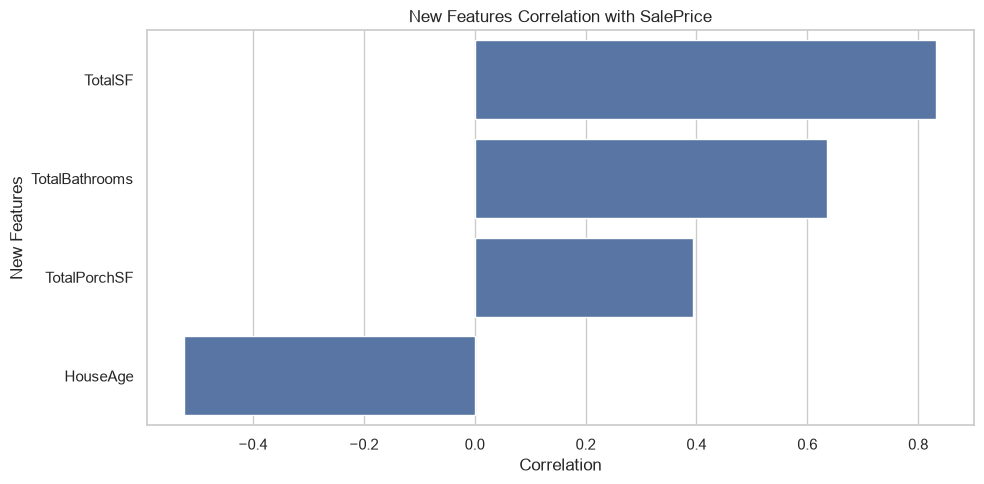

In [37]:
# Visualize new feature correlations

plt.figure(figsize=(10, 5))

sns.barplot(
    x=feature_correlations.drop("SalePrice").values,
    y=feature_correlations.drop("SalePrice").index
)

plt.title("New Features Correlation with SalePrice")
plt.xlabel("Correlation")
plt.ylabel("New Features")

plt.tight_layout()

plt.savefig(
    figures_dir / "new_features_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2 Feature Engineering Results

Four new features were created:

1. TotalSF: Total basement and above-ground living area.
2. TotalBathrooms: Total number of bathrooms, including half bathrooms.
3. HouseAge: Age of the house at the time of sale.
4. TotalPorchSF: Total porch and deck area.

These features combine existing columns into more meaningful
information that may help machine learning models predict
house prices more accurately.

The correlations with SalePrice were calculated and visualized.

In [38]:
# Save datasets with new features

train.to_csv(
    project_dir / "data/train_featured_temp.csv",
    index=False
)

test.to_csv(
    project_dir / "data/test_featured_temp.csv",
    index=False
)

print("Datasets with new features saved!")

Datasets with new features saved!


In [39]:
# Հատկանիշներից հեռացնում ենք թիրախը և դրա log տարբերակը
X_train = train.drop(columns=["SalePrice", "SalePriceLog"], errors="ignore")
X_test = test.drop(columns=["SalePriceLog"], errors="ignore")

# Id-ն պահում ենք առանձին, ոչ թե որպես մոդելի հատկանիշ
train_ids = X_train["Id"].copy()
test_ids = X_test["Id"].copy()

X_train = X_train.drop(columns=["Id"])
X_test = X_test.drop(columns=["Id"])

print("Train features:", X_train.shape)
print("Test features:", X_test.shape)

Train features: (1458, 83)
Test features: (1459, 83)


In [40]:
# Միավորում ենք train և test հատկանիշները
all_features = pd.concat(
    [X_train, X_test],
    axis=0,
    ignore_index=True
)

# Կատեգորիկ սյունակները դարձնում ենք թվային
all_features_encoded = pd.get_dummies(
    all_features,
    drop_first=False,
    dtype=int
)

# Բաժանում ենք նորից train և test
X_train_encoded = all_features_encoded.iloc[:len(X_train)].copy()
X_test_encoded = all_features_encoded.iloc[len(X_train):].copy()

print("Encoded train shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

Encoded train shape: (1458, 312)
Encoded test shape: (1459, 312)


In [41]:
# Ստուգում ենք՝ train և test հատկանիշների սյունակները նույնն են
print("Նույն սյունակներն են:", 
      X_train_encoded.columns.equals(X_test_encoded.columns))

# Ստուգում ենք բացակայող արժեքները
print("Train-ի բացակայող արժեքներ:", X_train_encoded.isnull().sum().sum())
print("Test-ի բացակայող արժեքներ:", X_test_encoded.isnull().sum().sum())

# Ստուգում ենք տվյալների չափերը
print("Train:", X_train_encoded.shape)
print("Test:", X_test_encoded.shape)

Նույն սյունակներն են: True
Train-ի բացակայող արժեքներ: 0
Test-ի բացակայող արժեքներ: 0
Train: (1458, 312)
Test: (1459, 312)


In [42]:
# Վերականգնում ենք Id սյունակը
train_processed = X_train_encoded.copy()
train_processed.insert(0, "Id", train_ids.values)

test_processed = X_test_encoded.copy()
test_processed.insert(0, "Id", test_ids.values)

# Train-ում պահում ենք նաև սկզբնական SalePrice թիրախը
train_processed["SalePrice"] = train["SalePrice"].values

print("Final train:", train_processed.shape)
print("Final test:", test_processed.shape)

Final train: (1458, 314)
Final test: (1459, 313)


In [43]:
# Ստեղծում ենք processed թղթապանակը, եթե այն դեռ չկա
processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Պահպանում ենք ֆայլերը
train_processed.to_csv(
    processed_dir / "train_processed.csv",
    index=False
)

test_processed.to_csv(
    processed_dir / "test_processed.csv",
    index=False
)

print("Ֆայլերը հաջողությամբ պահպանվեցին։")

Ֆայլերը հաջողությամբ պահպանվեցին։


In [44]:
# Կարդում ենք պահպանված ֆայլերը և ստուգում
saved_train = pd.read_csv(processed_dir / "train_processed.csv")
saved_test = pd.read_csv(processed_dir / "test_processed.csv")

print("Train file:", saved_train.shape)
print("Test file:", saved_test.shape)

print("\nTrain-ի առաջին 5 տողերը՝")
display(saved_train.head())

print("\nTest-ի առաջին 5 տողերը՝")
display(saved_test.head())

Train file: (1458, 314)
Test file: (1459, 313)

Train-ի առաջին 5 տողերը՝


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_None,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SalePrice
0,1,60,65.0,8450,7,5,2003,2003,196.0,706.0,...,0,0,1,0,0,0,0,1,0,208500
1,2,20,80.0,9600,6,8,1976,1976,0.0,978.0,...,0,0,1,0,0,0,0,1,0,181500
2,3,60,68.0,11250,7,5,2001,2002,162.0,486.0,...,0,0,1,0,0,0,0,1,0,223500
3,4,70,60.0,9550,7,5,1915,1970,0.0,216.0,...,0,0,1,1,0,0,0,0,0,140000
4,5,60,84.0,14260,8,5,2000,2000,350.0,655.0,...,0,0,1,0,0,0,0,1,0,250000



Test-ի առաջին 5 տողերը՝


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_New,SaleType_None,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1461,20,80.0,11622,5,6,1961,1961,0.0,468.0,...,0,0,0,1,0,0,0,0,1,0
1,1462,20,81.0,14267,6,6,1958,1958,108.0,923.0,...,0,0,0,1,0,0,0,0,1,0
2,1463,60,74.0,13830,5,5,1997,1998,0.0,791.0,...,0,0,0,1,0,0,0,0,1,0
3,1464,60,78.0,9978,6,6,1998,1998,20.0,602.0,...,0,0,0,1,0,0,0,0,1,0
4,1465,120,43.0,5005,8,5,1992,1992,0.0,263.0,...,0,0,0,1,0,0,0,0,1,0


In [45]:
train_processed.to_csv(
    processed_dir / "train_processed.csv",
    index=False
)

test_processed.to_csv(
    processed_dir / "test_processed.csv",
    index=False
)

print("Train saved:", (processed_dir / "train_processed.csv").exists())
print("Test saved:", (processed_dir / "test_processed.csv").exists())

Train saved: True
Test saved: True
